In [1]:
!pip -q install medmnist scikit-image scikit-learn opencv-python-headless seaborn

Imports and registration-specific settings

In [2]:
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import medmnist

from medmnist import INFO
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

SEED = 18
REGISTRATION = "FA23-BAI-018"
NAME = "Saud Ahmed"

CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = [
    "Eosinophil", "Monocyte", "Neutrophil", "Platelet"
]

HOG_CELL = (8, 8)
HOG_BLOCK = (2, 2)
HOG_ORIENTATIONS = 9
SIFT_GRID = 6
IMAGE_SIZE = (128, 128)
C_VALUES = [0.1, 1, 10]

random.seed(SEED)
np.random.seed(SEED)

print("Name:", NAME)
print("Registration:", REGISTRATION)
print("Random seed:", SEED)
print("HOG cell size:", HOG_CELL)
print("SIFT grid:", f"{SIFT_GRID} x {SIFT_GRID}")
print("SIFT keypoint size: 32")

Name: Saud Ahmed
Registration: FA23-BAI-018
Random seed: 18
HOG cell size: (8, 8)
SIFT grid: 6 x 6
SIFT keypoint size: 32


Download BloodMNIST and create the required subsets.  Q1


In [3]:
info = INFO["bloodmnist"]
Dataset = getattr(medmnist, info["python_class"])

train_ds = Dataset(split="train", download=True, size=64)
val_ds = Dataset(split="val", download=True, size=64)
test_ds = Dataset(split="test", download=True, size=64)

def unpack_dataset(dataset):
    images = np.asarray(dataset.imgs)
    labels = np.asarray(dataset.labels).reshape(-1).astype(int)
    return images, labels

train_raw, train_labels_raw = unpack_dataset(train_ds)
val_raw, val_labels_raw = unpack_dataset(val_ds)
test_raw, test_labels_raw = unpack_dataset(test_ds)

def select_subset(images, labels, per_class, seed):
    rng = np.random.default_rng(seed)
    selected_images = []
    selected_labels = []

    for class_id in CLASS_IDS:
        indices = np.flatnonzero(labels == class_id)

        if len(indices) < per_class:
            raise ValueError(
                f"Class {class_id} contains {len(indices)} images; "
                f"{per_class} are required."
            )

        chosen = rng.choice(indices, size=per_class, replace=False)
        selected_images.extend(images[chosen])
        selected_labels.extend(labels[chosen])

    order = rng.permutation(len(selected_labels))

    return (
        np.asarray(selected_images)[order],
        np.asarray(selected_labels, dtype=int)[order]
    )

train_raw, y_train = select_subset(
    train_raw, train_labels_raw, 100, SEED
)

val_raw, y_val = select_subset(
    val_raw, val_labels_raw, 30, SEED + 1
)

test_raw, y_test = select_subset(
    test_raw, test_labels_raw, 30, SEED + 2
)

print("Required subset counts:")
print("Train:", len(y_train), "| Expected: 400")
print("Validation:", len(y_val), "| Expected: 120")
print("Test:", len(y_test), "| Expected: 120")

100%|██████████| 156M/156M [01:39<00:00, 1.57MB/s]


Required subset counts:
Train: 400 | Expected: 400
Validation: 120 | Expected: 120
Test: 120 | Expected: 120


Grayscale conversion and resizing

In [4]:
def preprocess_image(image):
    image = np.asarray(image)

    if image.ndim == 3 and image.shape[-1] == 1:
        image = image[:, :, 0]

    elif image.ndim == 3:
        image = cv2.cvtColor(
            image.astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

    image = cv2.resize(
        image.astype(np.uint8),
        IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR
    )

    return image

X_train = np.stack([preprocess_image(im) for im in train_raw])
X_val = np.stack([preprocess_image(im) for im in val_raw])
X_test = np.stack([preprocess_image(im) for im in test_raw])

def print_split(name, images, labels):
    print(f"\n{name}")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

    counts = pd.Series(labels).value_counts()

    for class_id, class_name in zip(CLASS_IDS, CLASS_NAMES):
        print(f"{class_name}: {counts.get(class_id, 0)}")

print_split("TRAIN", X_train, y_train)
print_split("VALIDATION", X_val, y_val)
print_split("TEST", X_test, y_test)


TRAIN
Image shape: (400, 128, 128)
Label shape: (400,)
Eosinophil: 100
Monocyte: 100
Neutrophil: 100
Platelet: 100

VALIDATION
Image shape: (120, 128, 128)
Label shape: (120,)
Eosinophil: 30
Monocyte: 30
Neutrophil: 30
Platelet: 30

TEST
Image shape: (120, 128, 128)
Label shape: (120,)
Eosinophil: 30
Monocyte: 30
Neutrophil: 30
Platelet: 30


Display four images from each class

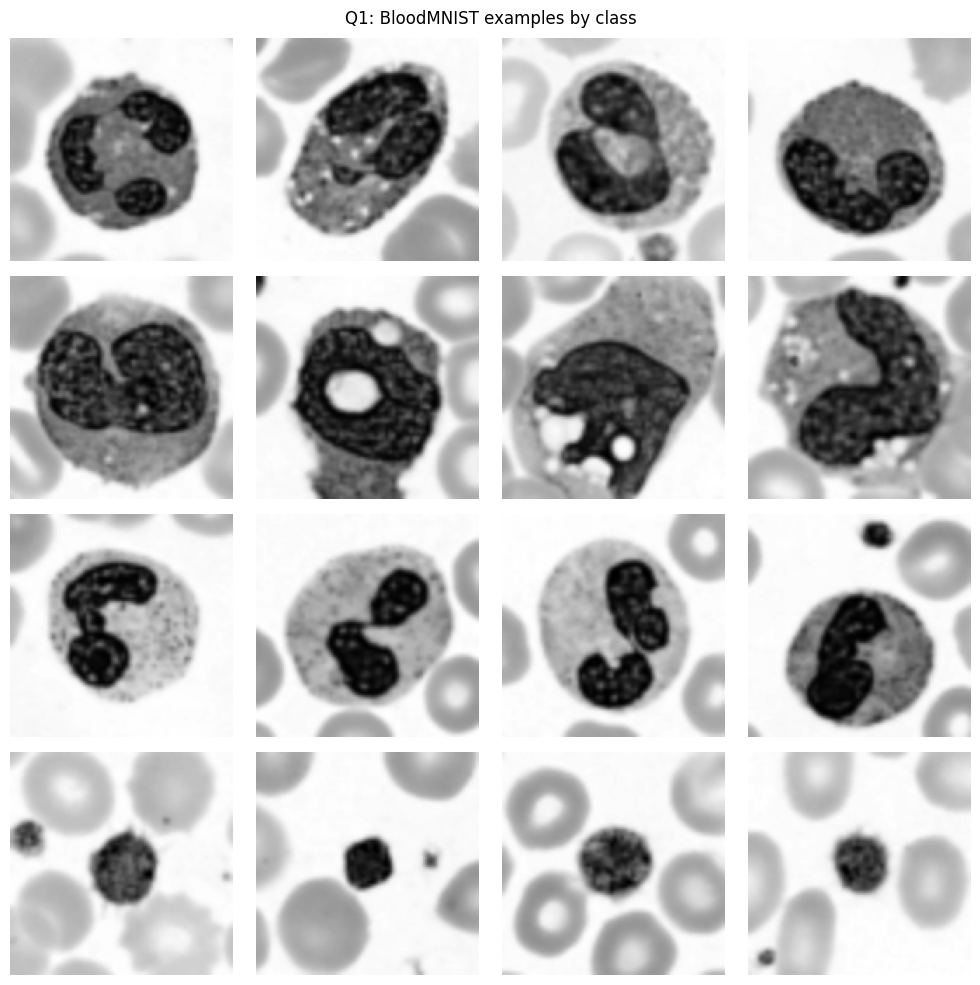

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for row, class_id in enumerate(CLASS_IDS):
    indices = np.flatnonzero(y_train == class_id)[:4]

    for col, idx in enumerate(indices):
        axes[row, col].imshow(X_train[idx], cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                CLASS_NAMES[row], fontsize=10
            )

plt.suptitle("Q1: BloodMNIST examples by class")
plt.tight_layout()
plt.show()

HOG + SVM
 — Extract HOG features and verify the feature length

In [6]:
def extract_hog(images, visualize=False):
    features = []
    visualizations = []

    for image in images:
        result = hog(
            image.astype(np.float32) / 255.0,
            orientations=HOG_ORIENTATIONS,
            pixels_per_cell=HOG_CELL,
            cells_per_block=HOG_BLOCK,
            block_norm="L2-Hys",
            visualize=visualize,
            feature_vector=True
        )

        if visualize:
            feature_vector, hog_image = result
            features.append(feature_vector)
            visualizations.append(hog_image)
        else:
            features.append(result)

    if visualize:
        return np.asarray(features), visualizations

    return np.asarray(features)

X_train_hog, hog_visuals = extract_hog(X_train, visualize=True)
X_val_hog = extract_hog(X_val)

print("Training HOG shape:", X_train_hog.shape)
print("Validation HOG shape:", X_val_hog.shape)
print("Manual calculation: 15 x 15 x 36 = 8100")

assert X_train_hog.shape[1] == 8100

Training HOG shape: (400, 8100)
Validation HOG shape: (120, 8100)
Manual calculation: 15 x 15 x 36 = 8100


Display HOG visualizations for all four classes

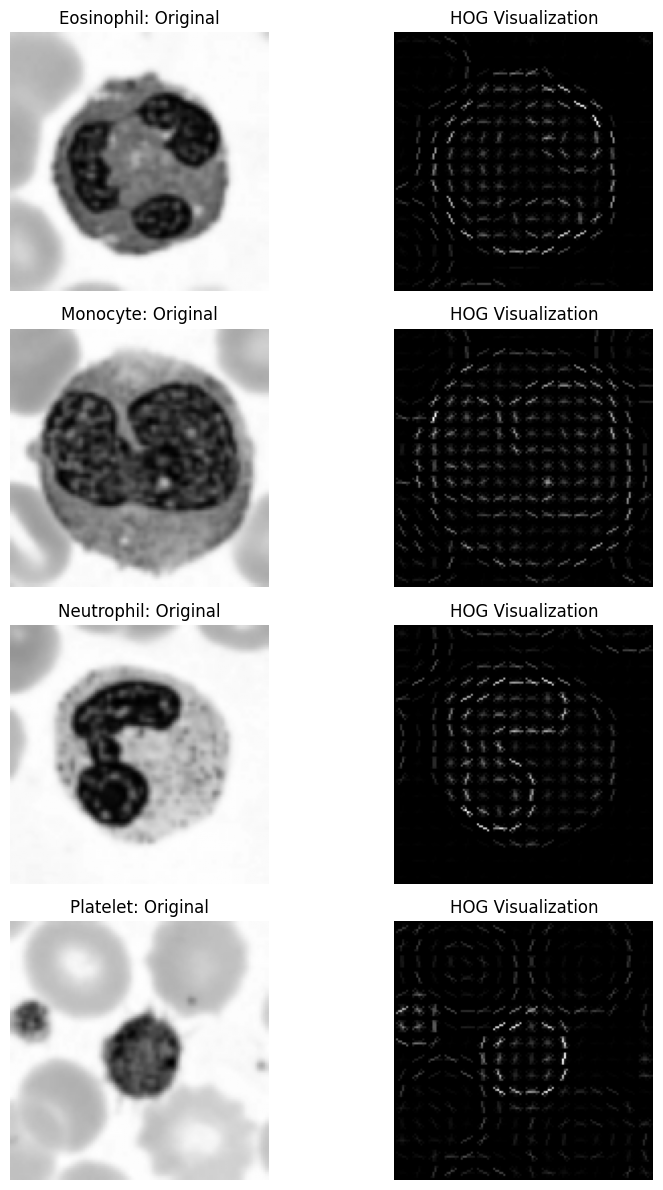

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(9, 12))

for row, class_id in enumerate(CLASS_IDS):
    idx = np.flatnonzero(y_train == class_id)[0]

    axes[row, 0].imshow(X_train[idx], cmap="gray")
    axes[row, 0].set_title(f"{CLASS_NAMES[row]}: Original")

    axes[row, 1].imshow(hog_visuals[idx], cmap="gray")
    axes[row, 1].set_title("HOG Visualization")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

Train HOG SVM and select C using validation

    Model    C  Validation accuracy  Validation macro-F1
HOG + SVM  0.1             0.716667             0.723061
HOG + SVM  1.0             0.716667             0.723061
HOG + SVM 10.0             0.716667             0.723061

Selected C: 0.1

HOG validation accuracy: 0.7167
HOG validation macro-F1: 0.7231
Confusion matrix (rows=true, columns=predicted):
[[20  7  3  0]
 [ 8 21  1  0]
 [ 4  8 18  0]
 [ 1  2  0 27]]


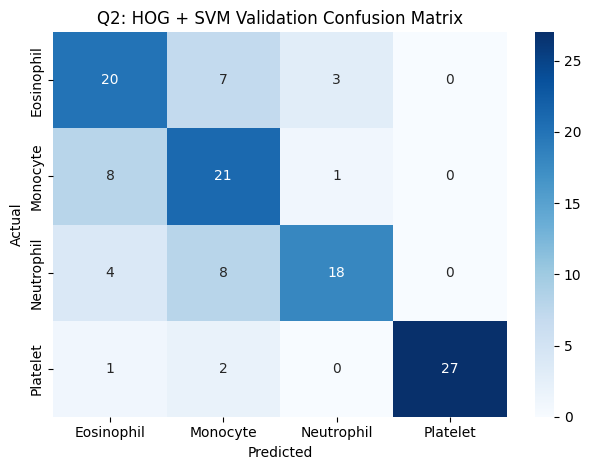

In [8]:
def train_and_select_svm(X_train_features, y_train,
                         X_validation_features, y_validation,
                         model_name):

    results = []
    fitted_models = {}

    for c in C_VALUES:
        model = make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=c,
                random_state=SEED,
                max_iter=20000
            )
        )

        model.fit(X_train_features, y_train)

        predictions = model.predict(X_validation_features)

        results.append({
            "Model": model_name,
            "C": c,
            "Validation accuracy": accuracy_score(
                y_validation, predictions
            ),
            "Validation macro-F1": f1_score(
                y_validation,
                predictions,
                average="macro",
                zero_division=0
            )
        })

        fitted_models[c] = model

    results_df = pd.DataFrame(results).sort_values(
        ["Validation macro-F1", "Validation accuracy"],
        ascending=False
    ).reset_index(drop=True)

    best_c = float(results_df.loc[0, "C"])

    print(results_df.to_string(index=False))
    print("\nSelected C:", best_c)

    return fitted_models[best_c], best_c, results_df

hog_model, hog_best_c, hog_selection = train_and_select_svm(
    X_train_hog,
    y_train,
    X_val_hog,
    y_val,
    "HOG + SVM"
)

hog_val_predictions = hog_model.predict(X_val_hog)

print("\nHOG validation accuracy:",
      round(accuracy_score(y_val, hog_val_predictions), 4))

print("HOG validation macro-F1:",
      round(f1_score(
          y_val, hog_val_predictions,
          average="macro", zero_division=0
      ), 4))

hog_val_cm = confusion_matrix(
    y_val, hog_val_predictions, labels=CLASS_IDS
)

print("Confusion matrix (rows=true, columns=predicted):")
print(hog_val_cm)

sns.heatmap(
    hog_val_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Q2: HOG + SVM Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Fixed-grid SIFT descriptors

In [10]:
# Create the SIFT detector first
sift = cv2.SIFT_create()

def create_grid_keypoints():
    coordinates = np.linspace(16, 112, SIFT_GRID)

    return [
        cv2.KeyPoint(float(x), float(y), 32.0)
        for y in coordinates
        for x in coordinates
    ]

GRID_KEYPOINTS = create_grid_keypoints()

print("Grid size:", SIFT_GRID, "x", SIFT_GRID)
print("Number of grid points:", len(GRID_KEYPOINTS))
print("Keypoint size: 32")
print("Descriptor length: 128")
print("Expected feature length: 36 x 128 = 4608")


def extract_sift_grid(images):
    all_features = []

    for image in images:
        requested_keypoints = create_grid_keypoints()

        returned_keypoints, descriptors = sift.compute(
            image, requested_keypoints
        )

        feature_matrix = np.zeros((36, 128), dtype=np.float32)

        if descriptors is not None and len(returned_keypoints) > 0:
            original_xy = np.array(
                [kp.pt for kp in requested_keypoints],
                dtype=np.float32
            )

            assigned = set()

            for kp, descriptor in zip(returned_keypoints, descriptors):
                point = np.asarray(kp.pt, dtype=np.float32)
                distances = np.sum((original_xy - point) ** 2, axis=1)

                for candidate in np.argsort(distances):
                    candidate = int(candidate)

                    if candidate not in assigned:
                        feature_matrix[candidate] = descriptor
                        assigned.add(candidate)
                        break

        all_features.append(feature_matrix.flatten())

    return np.asarray(all_features, dtype=np.float32)


X_train_sift = extract_sift_grid(X_train)
X_val_sift = extract_sift_grid(X_val)

print("SIFT training feature shape:", X_train_sift.shape)
print("SIFT validation feature shape:", X_val_sift.shape)
print("SIFT features per image:", X_train_sift.shape[1])

assert X_train_sift.shape[1] == 4608
assert X_val_sift.shape[1] == 4608

Grid size: 6 x 6
Number of grid points: 36
Keypoint size: 32
Descriptor length: 128
Expected feature length: 36 x 128 = 4608
SIFT training feature shape: (400, 4608)
SIFT validation feature shape: (120, 4608)
SIFT features per image: 4608


Train SIFT SVM and select C using validation

     Model    C  Validation accuracy  Validation macro-F1
SIFT + SVM  0.1             0.766667              0.76778
SIFT + SVM  1.0             0.766667              0.76778
SIFT + SVM 10.0             0.766667              0.76778

Selected C: 0.1

SIFT validation accuracy: 0.7667
SIFT validation macro-F1: 0.7678
Confusion matrix (rows=true, columns=predicted):
[[17 11  2  0]
 [ 7 22  0  1]
 [ 3  2 24  1]
 [ 0  1  0 29]]


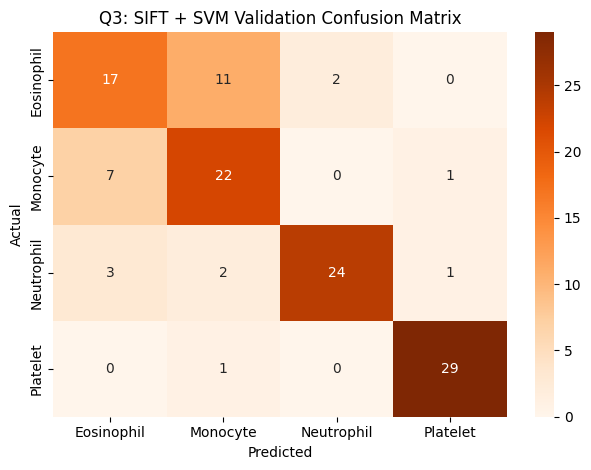

In [11]:
sift_model, sift_best_c, sift_selection = train_and_select_svm(
    X_train_sift,
    y_train,
    X_val_sift,
    y_val,
    "SIFT + SVM"
)

sift_val_predictions = sift_model.predict(X_val_sift)

print("\nSIFT validation accuracy:",
      round(accuracy_score(y_val, sift_val_predictions), 4))

print("SIFT validation macro-F1:",
      round(f1_score(
          y_val, sift_val_predictions,
          average="macro", zero_division=0
      ), 4))

sift_val_cm = confusion_matrix(
    y_val, sift_val_predictions, labels=CLASS_IDS
)

print("Confusion matrix (rows=true, columns=predicted):")
print(sift_val_cm)

sns.heatmap(
    sift_val_cm, annot=True, fmt="d", cmap="Oranges",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title("Q3: SIFT + SVM Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Rotation and Gaussian noise

Clean test images: (120, 128, 128)
Rotated test images: (120, 128, 128)
Noisy test images: (120, 128, 128)


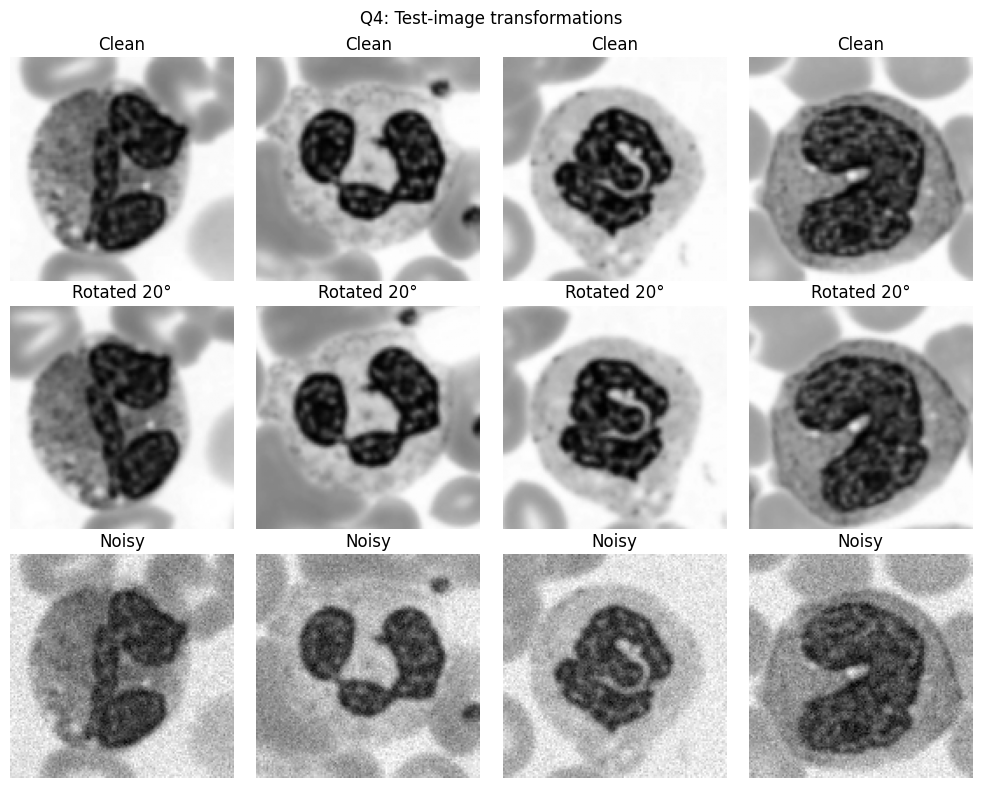

In [12]:
def rotate_image(image, angle=20):
    height, width = image.shape

    matrix = cv2.getRotationMatrix2D(
        (width / 2, height / 2), angle, 1.0
    )

    return cv2.warpAffine(
        image,
        matrix,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

def add_gaussian_noise(image, sigma=0.05, seed=SEED):
    rng = np.random.default_rng(seed)

    scaled = image.astype(np.float32) / 255.0

    noisy = scaled + rng.normal(
        loc=0.0,
        scale=sigma,
        size=scaled.shape
    )

    noisy = np.clip(noisy, 0.0, 1.0)

    return (noisy * 255).round().astype(np.uint8)

# Create transformed test images, without training on them.
X_test_rotated = np.stack([
    rotate_image(image, 20) for image in X_test
])

X_test_noisy = np.stack([
    add_gaussian_noise(image, 0.05, SEED + i)
    for i, image in enumerate(X_test)
])

print("Clean test images:", X_test.shape)
print("Rotated test images:", X_test_rotated.shape)
print("Noisy test images:", X_test_noisy.shape)

# Visual check
fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for col in range(4):
    axes[0, col].imshow(X_test[col], cmap="gray")
    axes[0, col].set_title("Clean")

    axes[1, col].imshow(X_test_rotated[col], cmap="gray")
    axes[1, col].set_title("Rotated 20°")

    axes[2, col].imshow(X_test_noisy[col], cmap="gray")
    axes[2, col].set_title("Noisy")

    for row in range(3):
        axes[row, col].axis("off")

plt.suptitle("Q4: Test-image transformations")
plt.tight_layout()
plt.show()

Evaluate the frozen models

In [13]:
test_cases = {
    "Clean": X_test,
    "Rotated 20 degrees": X_test_rotated,
    "Gaussian noise sigma=0.05": X_test_noisy
}

models = {
    "HOG + SVM": (hog_model, extract_hog),
    "SIFT + SVM": (sift_model, extract_sift_grid)
}

results = []
test_predictions = {}

for model_name, (model, feature_function) in models.items():

    for condition, images in test_cases.items():

        # Feature extraction occurs only during Q4.
        features = feature_function(images)

        predictions = model.predict(features)
        test_predictions[(model_name, condition)] = predictions

        results.append({
            "Model": model_name,
            "Condition": condition,
            "Accuracy": accuracy_score(y_test, predictions),
            "Macro-F1": f1_score(
                y_test,
                predictions,
                average="macro",
                zero_division=0
            ),
            "Precision (macro)": precision_score(
                y_test, predictions,
                average="macro", zero_division=0
            ),
            "Recall (macro)": recall_score(
                y_test, predictions,
                average="macro", zero_division=0
            )
        })

results_df = pd.DataFrame(results)

print("Q4: Robustness results")
display(results_df.round(4))

Q4: Robustness results


,Model,Condition,Accuracy,Macro-F1,Precision (macro),Recall (macro)
0,HOG + SVM,Clean,0.7083,0.7113,0.7151,0.7083
1,HOG + SVM,Rotated 20 degrees,0.7250,0.7281,0.7387,0.7250
2,HOG + SVM,Gaussian noise sigma=0.05,0.2500,0.1000,0.0625,0.2500
3,SIFT + SVM,Clean,0.6833,0.6805,0.6865,0.6833
4,SIFT + SVM,Rotated 20 degrees,0.6833,0.6856,0.6924,0.6833
5,SIFT + SVM,Gaussian noise sigma=0.05,0.6917,0.6844,0.6840,0.6917


Accuracy comparison table

In [14]:
accuracy_table = results_df.pivot(
    index="Model",
    columns="Condition",
    values="Accuracy"
)

print("Required comparison table: accuracy (%)")
display((accuracy_table * 100).round(2))

# Save this table for the report.
accuracy_table_percent = (accuracy_table * 100).round(2)

Required comparison table: accuracy (%)


Condition,Clean,Gaussian noise sigma=0.05,Rotated 20 degrees
Model,,,
HOG + SVM,70.83,25.00,72.50
SIFT + SVM,68.33,69.17,68.33


Accuracy and macro-F1 graphs

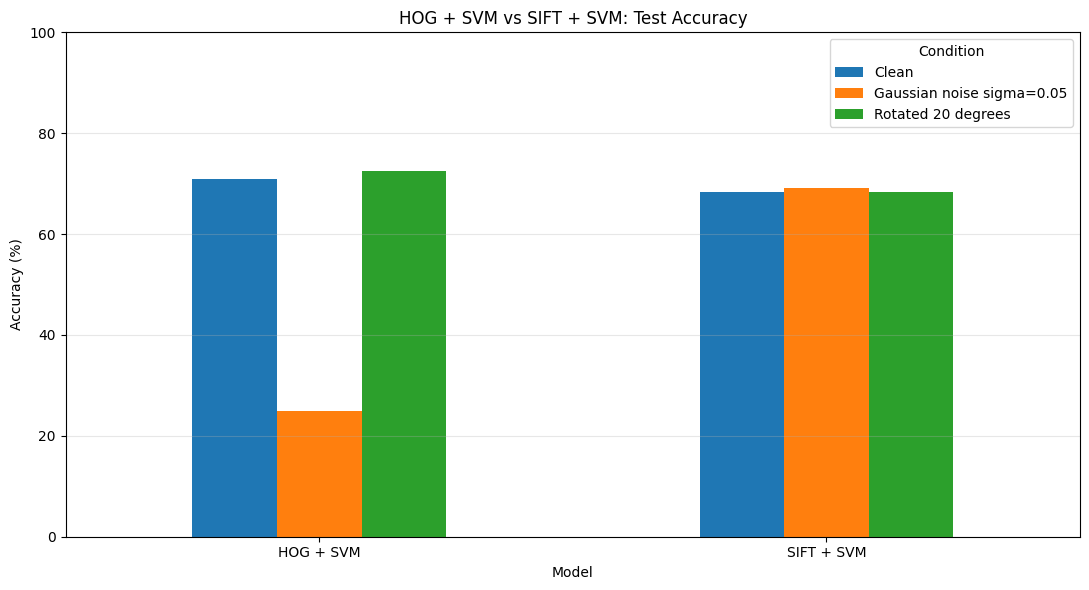

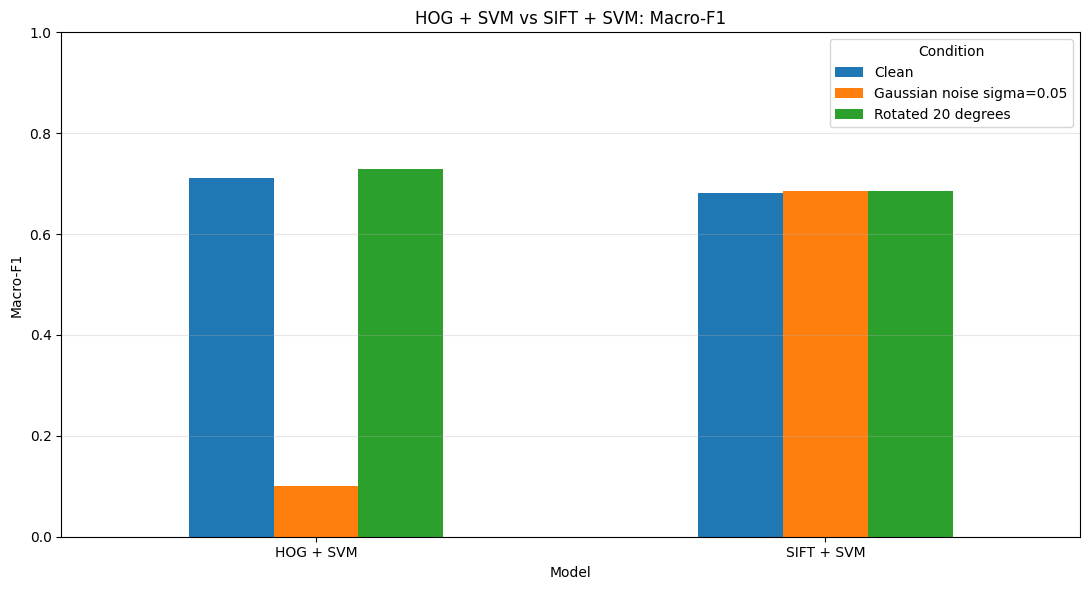

In [15]:
ax = (accuracy_table * 100).plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("HOG + SVM vs SIFT + SVM: Test Accuracy")
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Model")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

f1_table = results_df.pivot(
    index="Model",
    columns="Condition",
    values="Macro-F1"
)

ax = f1_table.plot(kind="bar", figsize=(11, 6))
ax.set_title("HOG + SVM vs SIFT + SVM: Macro-F1")
ax.set_ylabel("Macro-F1")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("macro_f1_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

Confusion matrices and most-confused classes


 HOG + SVM
Rows = actual; columns = predicted
[[15 11  4  0]
 [ 8 19  3  0]
 [ 5  2 23  0]
 [ 2  0  0 28]]
Largest directed confusion: Eosinophil predicted as Monocyte | Count: 11


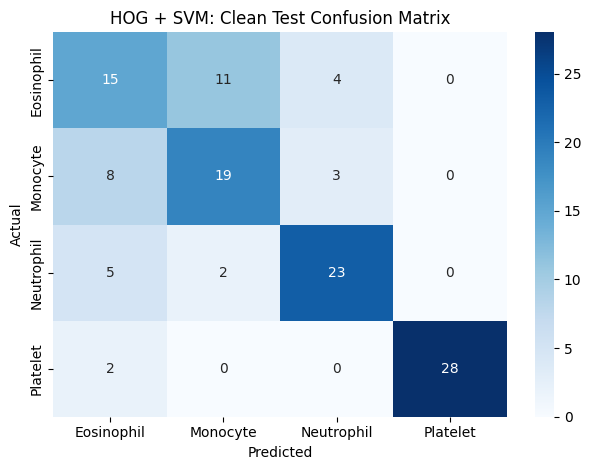


 SIFT + SVM
Rows = actual; columns = predicted
[[16  6  7  1]
 [11 15  4  0]
 [ 7  1 21  1]
 [ 0  0  0 30]]
Largest directed confusion: Monocyte predicted as Eosinophil | Count: 11


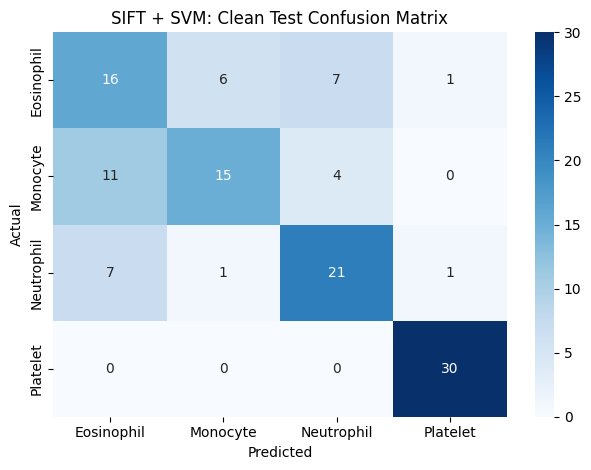

In [16]:
confusion_results = {}

for model_name in models:

    predictions = test_predictions[(model_name, "Clean")]

    cm = confusion_matrix(
        y_test, predictions, labels=CLASS_IDS
    )

    confusion_results[model_name] = cm

    print("\n", model_name)
    print("Rows = actual; columns = predicted")
    print(cm)

    # Identify the largest off-diagonal confusion.
    cm_off_diagonal = cm.copy()
    np.fill_diagonal(cm_off_diagonal, 0)

    i, j = np.unravel_index(
        np.argmax(cm_off_diagonal),
        cm_off_diagonal.shape
    )

    print(
        "Largest directed confusion:",
        f"{CLASS_NAMES[i]} predicted as {CLASS_NAMES[j]}",
        "| Count:", int(cm_off_diagonal[i, j])
    )

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"{model_name}: Clean Test Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

TP, TN, FP, FN, precision, recall

In [17]:
class_metric_rows = []

for model_name in models:

    predictions = test_predictions[(model_name, "Clean")]

    cm = confusion_matrix(
        y_test, predictions, labels=CLASS_IDS
    )

    total = cm.sum()

    for i, class_name in enumerate(CLASS_NAMES):

        tp = int(cm[i, i])
        fn = int(cm[i, :].sum() - tp)
        fp = int(cm[:, i].sum() - tp)
        tn = int(total - tp - fn - fp)

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        specificity = tn / (tn + fp) if tn + fp else 0.0

        class_metric_rows.append({
            "Model": model_name,
            "Class": class_name,
            "TP": tp,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "Specificity": specificity
        })

class_metrics_df = pd.DataFrame(class_metric_rows)
display(class_metrics_df.round(4))

,Model,Class,TP,TN,FP,FN,Precision,Recall,Specificity
0,HOG + SVM,Eosinophil,15,75,15,15,0.5000,0.5000,0.8333
1,HOG + SVM,Monocyte,19,77,13,11,0.5938,0.6333,0.8556
2,HOG + SVM,Neutrophil,23,83,7,7,0.7667,0.7667,0.9222
3,HOG + SVM,Platelet,28,90,0,2,1.0000,0.9333,1.0000
4,SIFT + SVM,Eosinophil,16,72,18,14,0.4706,0.5333,0.8000
5,SIFT + SVM,Monocyte,15,83,7,15,0.6818,0.5000,0.9222
6,SIFT + SVM,Neutrophil,21,79,11,9,0.6562,0.7000,0.8778
7,SIFT + SVM,Platelet,30,88,2,0,0.9375,1.0000,0.9778


Result

In [18]:
for model_name in models:
    clean = accuracy_table.loc[model_name, "Clean"]
    rotated = accuracy_table.loc[model_name, "Rotated 20 degrees"]
    noisy = accuracy_table.loc[model_name, "Gaussian noise sigma=0.05"]

    print(f"\n{model_name}")
    print(f"Clean accuracy:   {clean * 100:.2f}%")
    print(f"Rotated accuracy: {rotated * 100:.2f}%")
    print(f"Noisy accuracy:   {noisy * 100:.2f}%")
    print(f"Rotation change:  {(rotated - clean) * 100:+.2f} percentage points")
    print(f"Noise change:     {(noisy - clean) * 100:+.2f} percentage points")


HOG + SVM
Clean accuracy:   70.83%
Rotated accuracy: 72.50%
Noisy accuracy:   25.00%
Rotation change:  +1.67 percentage points
Noise change:     -45.83 percentage points

SIFT + SVM
Clean accuracy:   68.33%
Rotated accuracy: 68.33%
Noisy accuracy:   69.17%
Rotation change:  +0.00 percentage points
Noise change:     +0.83 percentage points


Final comparison table and winner

In [19]:
final_rows = []

for model_name in models:
    subset = results_df[results_df["Model"] == model_name]

    row = {
        "Model": model_name,
        "Selected C": (
            hog_best_c if model_name == "HOG + SVM"
            else sift_best_c
        )
    }

    for condition in test_cases:
        matching = subset[subset["Condition"] == condition].iloc[0]
        row[f"{condition} Accuracy"] = matching["Accuracy"]
        row[f"{condition} Macro-F1"] = matching["Macro-F1"]

    final_rows.append(row)

final_comparison = pd.DataFrame(final_rows)

display(final_comparison.round(4))

best_clean = final_comparison.sort_values(
    ["Clean Accuracy", "Clean Macro-F1"],
    ascending=False
).iloc[0]["Model"]

best_rotation = accuracy_table["Rotated 20 degrees"].idxmax()
best_noise = accuracy_table["Gaussian noise sigma=0.05"].idxmax()

print("Best clean-test result:", best_clean)
print("Best rotation accuracy:", best_rotation)
print("Best noise accuracy:", best_noise)

,Model,Selected C,Clean Accuracy,Clean Macro-F1,Rotated 20 degrees Accuracy,Rotated 20 degrees Macro-F1,Gaussian noise sigma=0.05 Accuracy,Gaussian noise sigma=0.05 Macro-F1
0,HOG + SVM,0.1,0.7083,0.7113,0.7250,0.7281,0.2500,0.1000
1,SIFT + SVM,0.1,0.6833,0.6805,0.6833,0.6856,0.6917,0.6844


Best clean-test result: HOG + SVM
Best rotation accuracy: HOG + SVM
Best noise accuracy: SIFT + SVM


q5_answers = """
Q5(a) Why does HOG use block normalization?
Block normalization reduces sensitivity to illumination and local contrast
changes by scaling gradient histograms. L2-Hys also limits the influence
of unusually large gradient values.

Q5(b) Why is choosing C using the test set wrong?
It leaks information from the final evaluation set into model selection
and can produce an optimistically biased estimate. C must be selected
using validation data; the test set is reserved for final evaluation.

Q5(c) Which classes were confused most?
Use the actual clean-test confusion matrices above. Name the class pair
with the largest off-diagonal confusion for each model. Grayscale removes
colour cues, which can make visually similar cell classes harder to
distinguish.

Q5(d) AI log
Prompt: Build Q1-Q5 BloodMNIST HOG/SIFT + SVM notebook according to
the supplied lab instructions.
Change: Applied registration-specific settings and implemented fixed-grid
SIFT features with fixed-length output.
Check: Printed split shapes/counts and feature lengths; inspected images,
HOG/keypoint visualizations, metrics and confusion matrices.
"""
print(q5_answers)

In [23]:
import cv2
import numpy as np

# Recreate the SIFT detector
sift = cv2.SIFT_create()

# Calculate normal SIFT keypoint counts on training images
keypoint_counts = []

for image in X_train:
    keypoints, descriptors = sift.detectAndCompute(
        image.astype(np.uint8), None
    )
    keypoint_counts.append(len(keypoints))

keypoint_counts = np.asarray(keypoint_counts)

print("Average keypoints:", round(float(keypoint_counts.mean()), 2))
print("Minimum keypoints:", int(keypoint_counts.min()))
print("Maximum keypoints:", int(keypoint_counts.max()))
print("Images with zero keypoints:", int(np.sum(keypoint_counts == 0)))

Average keypoints: 71.92
Minimum keypoints: 10
Maximum keypoints: 187
Images with zero keypoints: 0


In [24]:
import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.backends.backend_pdf import PdfPages
from google.colab import files

# =========================================================
# 1. CHECK THAT THE PREVIOUS NOTEBOOK CELLS HAVE RUN
# =========================================================

required_variables = [
    "results_df",
    "final_comparison",
    "class_metrics_df",
    "X_train",
    "X_val",
    "X_test",
    "y_train",
    "y_val",
    "y_test",
    "hog_model",
    "sift_model",
    "hog_best_c",
    "sift_best_c",
    "hog_val_cm",
    "sift_val_cm",
    "keypoint_counts",
    "accuracy_table",
    "test_predictions",
    "models",
    "test_cases"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run all notebook cells from Cell 1 to Cell 19 first. "
        "Missing variables: " + ", ".join(missing)
    )

NAME = "Saud Ahmed"
REGISTRATION = "FA23-BAI-018"

md_path = "FA23-BAI-018_Saud_Ahmed_LabMid.md"
pdf_path = "FA23-BAI-018_Saud_Ahmed_LabMid.pdf"

# =========================================================
# 2. PREPARE ACTUAL RESULTS
# =========================================================

hog_val_predictions = hog_model.predict(
    extract_hog(X_val)
)

sift_val_predictions = sift_model.predict(
    extract_sift_grid(X_val)
)

hog_val_accuracy = float(
    np.mean(hog_val_predictions == y_val)
)

sift_val_accuracy = float(
    np.mean(sift_val_predictions == y_val)
)

hog_val_f1 = float(
    __import__("sklearn.metrics", fromlist=["f1_score"])
    .f1_score(y_val, hog_val_predictions,
              average="macro", zero_division=0)
)

sift_val_f1 = float(
    __import__("sklearn.metrics", fromlist=["f1_score"])
    .f1_score(y_val, sift_val_predictions,
              average="macro", zero_division=0)
)

results_text = results_df.round(4).to_string(index=False)
comparison_text = final_comparison.round(4).to_string(index=False)
metrics_text = class_metrics_df.round(4).to_string(index=False)

# =========================================================
# 3. CREATE THE MARKDOWN REPORT
# =========================================================

markdown_report = f"""
# Computer Vision Lab Mid Exam
## HOG vs SIFT on BloodMNIST

**Name:** {NAME}
**Registration:** {REGISTRATION}
**Dataset:** BloodMNIST (MedMNIST, size 64)

## Q1 — Dataset setup

- Training images: {X_train.shape}
- Validation images: {X_val.shape}
- Test images: {X_test.shape}
- Classes: Eosinophil, Monocyte, Neutrophil, Platelet
- Images per class: 100 training, 30 validation, 30 test
- Image preprocessing: grayscale and resize to 128 × 128
- Random seed: 18

The notebook displays four example images for each class.

## Q2 — HOG + SVM

HOG settings:
- Cell size: 8 × 8
- Orientations: 9
- Block size: 2 × 2 cells
- Normalization: L2-Hys

Feature calculation:

- Cells per dimension = 128 / 8 = 16
- Blocks per dimension = 16 - 2 + 1 = 15
- Values per block = 2 × 2 × 9 = 36
- Total features = 15 × 15 × 36 = **8,100**

Selected C: {hog_best_c}
Validation accuracy: {hog_val_accuracy:.4f}
Validation macro-F1: {hog_val_f1:.4f}

Confusion matrix (rows = actual; columns = predicted):

{np.array2string(hog_val_cm)}

## Q3 — SIFT + SVM

Normal SIFT keypoint statistics:

- Average keypoints: {np.mean(keypoint_counts):.2f}
- Minimum keypoints: {np.min(keypoint_counts)}
- Maximum keypoints: {np.max(keypoint_counts)}
- Images with zero keypoints: {np.sum(keypoint_counts == 0)}

Fixed-grid SIFT settings:

- Grid: 6 × 6
- Keypoints: 36
- Keypoint size: 32
- Descriptor length: 128
- Expected feature length: 36 × 128 = **4,608**

Selected C: {sift_best_c}
Validation accuracy: {sift_val_accuracy:.4f}
Validation macro-F1: {sift_val_f1:.4f}

Confusion matrix (rows = actual; columns = predicted):

{np.array2string(sift_val_cm)}

Normal SIFT can produce different numbers of descriptors for different
images. Fixed-length feature vectors are required for standard SVM input.

## Q4 — Robustness testing

The test set is used for final evaluation only. C was selected using
validation data.

### Actual results

{results_text}

### Model comparison

{comparison_text}

### Class-level metrics

{metrics_text}

The notebook's accuracy and macro-F1 graphs are included in the PDF
when their image files are available.

**Interpretation:** Compare clean, rotated 20-degree and Gaussian-noise
results. State whether the original prediction was supported by the
actual results; do not assume one method is better in advance.

## Q5 — Short answers

### (a) Why does HOG use block normalization?

Block normalization scales local gradient histograms, reducing sensitivity
to illumination and contrast changes. L2-Hys also limits the influence
of unusually large gradient values.

### (b) Why must C not be selected using the test set?

Selecting C on test data leaks information from the final evaluation set
into model selection and can bias the performance estimate. C must be
selected using validation data.

### (c) Which classes were confused most?

Use the clean-test confusion matrices in the notebook to identify the
largest off-diagonal entry for each model. Grayscale removes colour cues,
which can make visually similar blood-cell classes harder to distinguish.

### (d) AI log

| Prompt | Change | Check |
|---|---|---|
| Build the Q1-Q5 HOG/SIFT lab notebook | Applied registration-specific settings and fixed-grid SIFT | Checked feature lengths, plots, metrics and confusion matrices |

## Formulas

- Accuracy = (TP + TN) / (TP + TN + FP + FN)
- Precision = TP / (TP + FP)
- Recall = TP / (TP + FN)
- Specificity = TN / (TN + FP)
- F1 = 2 × Precision × Recall / (Precision + Recall)
- Macro-F1 = average of the per-class F1 scores

For multiclass classification, TP, TN, FP and FN are computed separately
for each class using a one-vs-rest approach.

## Conclusion

Compare HOG + SVM and SIFT + SVM using validation results and the three
test conditions. Base the final conclusion on the actual measured values,
not on the initial prediction.

**Reproducibility:** Results depend on the data subset, random seed,
library versions and execution environment.
"""

with open(md_path, "w", encoding="utf-8") as f:
    f.write(markdown_report)

print("Markdown report created:", md_path)

# =========================================================
# 4. CREATE THE PDF WITHOUT REPORTLAB
# =========================================================

def add_pdf_text_page(pdf, title, body, fontsize=9):
    """Create a PDF page containing wrapped text."""
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.patch.set_facecolor("white")

    fig.text(
        0.08, 0.95, title,
        fontsize=16, fontweight="bold",
        va="top"
    )

    wrapped_lines = []

    for paragraph in str(body).split("\n"):
        if not paragraph.strip():
            wrapped_lines.append("")
        else:
            wrapped_lines.extend(
                textwrap.wrap(
                    paragraph,
                    width=100,
                    replace_whitespace=False,
                    break_long_words=True
                ) or [""]
            )

    y = 0.90
    line_height = 0.019 if fontsize <= 9 else 0.022

    for line in wrapped_lines:
        if y < 0.06:
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

            fig = plt.figure(figsize=(8.27, 11.69))
            fig.patch.set_facecolor("white")
            fig.text(
                0.08, 0.95, title + " (continued)",
                fontsize=14, fontweight="bold",
                va="top"
            )
            y = 0.90

        fig.text(
            0.08, y, line,
            fontsize=fontsize,
            family="monospace" if len(line) > 70 else "sans-serif",
            va="top"
        )
        y -= line_height

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)


with PdfPages(pdf_path) as pdf:

    add_pdf_text_page(
        pdf,
        "Computer Vision Lab Mid Exam",
        f"Name: {NAME}\n"
        f"Registration: {REGISTRATION}\n"
        "Topic: HOG vs SIFT on BloodMNIST\n\n"
        "Q1 - Dataset Setup\n"
        f"Training shape: {X_train.shape}\n"
        f"Validation shape: {X_val.shape}\n"
        f"Test shape: {X_test.shape}\n"
        "Image size: 128 x 128 grayscale\n"
        "Classes: Eosinophil, Monocyte, Neutrophil, Platelet\n"
        "Subset: 100 training, 30 validation, 30 test images per class\n\n"
        "Q2 - HOG + SVM\n"
        "Cells per dimension: 128 / 8 = 16\n"
        "Blocks per dimension: 16 - 2 + 1 = 15\n"
        "Values per block: 2 x 2 x 9 = 36\n"
        "Total HOG features: 15 x 15 x 36 = 8100\n"
        f"Selected C: {hog_best_c}\n"
        f"Validation accuracy: {hog_val_accuracy:.4f}\n"
        f"Validation macro-F1: {hog_val_f1:.4f}\n\n"
        "HOG validation confusion matrix:\n"
        + np.array2string(hog_val_cm)
    )

    add_pdf_text_page(
        pdf,
        "Q3 - SIFT + SVM",
        f"Average normal SIFT keypoints: {np.mean(keypoint_counts):.2f}\n"
        f"Minimum keypoints: {np.min(keypoint_counts)}\n"
        f"Maximum keypoints: {np.max(keypoint_counts)}\n"
        f"Zero-keypoint images: {np.sum(keypoint_counts == 0)}\n\n"
        "Fixed grid: 6 x 6 = 36 keypoints\n"
        "Keypoint size: 32\n"
        "Descriptor length: 128\n"
        "Feature length: 36 x 128 = 4608\n\n"
        f"Selected C: {sift_best_c}\n"
        f"Validation accuracy: {sift_val_accuracy:.4f}\n"
        f"Validation macro-F1: {sift_val_f1:.4f}\n\n"
        "SIFT validation confusion matrix:\n"
        + np.array2string(sift_val_cm)
    )

    add_pdf_text_page(
        pdf,
        "Q4 - Robustness Results",
        results_text + "\n\nMODEL COMPARISON\n\n" + comparison_text,
        fontsize=8
    )

    add_pdf_text_page(
        pdf,
        "Q4 - Class-Level Metrics",
        metrics_text,
        fontsize=8
    )

    add_pdf_text_page(
        pdf,
        "Q5 - Answers and Formulas",
        "1. HOG block normalization:\n"
        "It scales local gradient histograms to reduce sensitivity to "
        "illumination and contrast changes. L2-Hys limits large values.\n\n"
        "2. Why not choose C on the test set?\n"
        "That leaks final evaluation information into model selection. "
        "Use validation data to select C and reserve test data for final evaluation.\n\n"
        "3. Most confused classes:\n"
        "Use the largest off-diagonal entry in each clean-test confusion matrix. "
        "Grayscale removes colour information and may make similar classes harder to distinguish.\n\n"
        "4. AI log:\n"
        "Prompt: Build Q1-Q5 HOG/SIFT lab notebook.\n"
        "Change: Registration-specific settings and fixed-grid SIFT.\n"
        "Check: Feature lengths, plots, metrics and confusion matrices.\n\n"
        "FORMULAS\n"
        "Accuracy = (TP+TN)/(TP+TN+FP+FN)\n"
        "Precision = TP/(TP+FP)\n"
        "Recall = TP/(TP+FN)\n"
        "Specificity = TN/(TN+FP)\n"
        "F1 = 2*Precision*Recall/(Precision+Recall)\n"
        "Macro-F1 = mean of per-class F1 scores."
    )

    # Add the graphs if they were created by Cell 15.
    for image_file in [
        "accuracy_comparison.png",
        "macro_f1_comparison.png"
    ]:
        if os.path.exists(image_file):
            image = plt.imread(image_file)
            fig = plt.figure(figsize=(8.27, 11.69))
            plt.imshow(image)
            plt.axis("off")
            plt.title(image_file.replace("_", " ").replace(".png", ""))
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

print("PDF report created:", pdf_path)

# =========================================================
# 5. VERIFY FILES AND DOWNLOAD BOTH
# =========================================================

for path in [md_path, pdf_path]:
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        raise RuntimeError("File was not created correctly: " + path)

    print(f"{path} | {os.path.getsize(path):,} bytes")

files.download(md_path)
files.download(pdf_path)

Markdown report created: FA23-BAI-018_Saud_Ahmed_LabMid.md
PDF report created: FA23-BAI-018_Saud_Ahmed_LabMid.pdf
FA23-BAI-018_Saud_Ahmed_LabMid.md | 5,678 bytes
FA23-BAI-018_Saud_Ahmed_LabMid.pdf | 92,467 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>